# Predicción de incidentes viales en la Ciudad de Buenos Aires
## Notebook 1 — EDA y limpieza de datos

**Fuente (Buenos Aires Data):** [Víctimas de siniestros viales](https://data.buenosaires.gob.ar/dataset/victimas-siniestros-viales) — tablas `hechos` y `víctimas`, CABA.

**Recorrido**

| Parte | Secciones | Qué se hace |
|---|---|---|
| **1 — EDA** | 1 a 9 | se *diagnostica*: estructura, faltantes, duplicados, categóricas, distribuciones, atípicos y coherencia. **No se modifica ningún dato.** |
| **2 — Limpieza** | 10 a 20 | se aplican las decisiones que el EDA justificó, sobre una copia y registrando cada cambio en una bitácora. |

**Principio rector:** cada decisión de limpieza modifica los datos y por lo tanto las conclusiones. Se usan sólo `pandas`, `matplotlib` y `seaborn`.

---
# Parte 1 — Análisis Exploratorio de Datos

## 1. Carga de los datos

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 60)

In [65]:
# En Colab hay que montar Drive; si no estamos en Colab, este paso se saltea.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA = "/content/drive/MyDrive/datos/"
except ImportError:
    RUTA = ""          # ejecución local: los CSV están en la misma carpeta del notebook

print("Ruta de los datos:", RUTA if RUTA else "(carpeta actual)")

Ruta de los datos: (carpeta actual)


In [66]:
hechos_raw = pd.read_csv(RUTA + "siniestros_viales_hechos.csv",
                         sep=";", encoding="utf-8-sig", low_memory=False)
victimas_raw = pd.read_csv(RUTA + "siniestros_viales_victimas.csv",
                           sep=";", encoding="utf-8-sig", low_memory=False)

print("hechos  :", hechos_raw.shape)
print("victimas:", victimas_raw.shape)

hechos  : (65818, 21)
victimas: (75197, 9)


## 2. Conociendo nuestros datasets

¿Cuántas filas y columnas hay?, ¿qué representa cada fila?, ¿qué tipo de dato tiene cada variable?

In [67]:
hechos_raw.head(3)

,id_siniestro,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,hora_siniestro,rango_horario,direccion_normalizada_siniestro,comuna_siniestro,tipo_de_via_siniestro,geocodificacion_plana,longitud_siniestro,latitud_siniestro,participantes_siniestro,modo_desplazamiento_victima,contraparte_siniestro,gravedad_siniestro
0,LC-2019-0000053,1,1,0,0,2019-01-01,2019,1,1,01:55:00,1,NaN,Comuna 8,AUTOPISTA,POINT (101813.84712503915943671 95578.55507230...,-58.44351,-34.669125,AUTO-UTILITARIO,AUTO,UTILITARIO,LEVE
1,LC-2019-0000647,1,0,1,0,2019-01-01,2019,1,1,18:50:00,18,DE LOS CONSTITUYENTES AV. y HABANA,Comuna 12,AVENIDA,POINT (97510.27137648081406951 105087.83369881...,-58.490436,-34.583403,MOTO-AUTO,MOTO,AUTO,GRAVE
2,LC-2019-0000445,3,3,0,0,2019-01-01,2019,1,1,13:40:00,13,NaN,Comuna 11,NaN,POINT (94371.44237885093025398 102884.19365105...,-58.524662,-34.603255,AUTO-AUTO,AUTO,AUTO,LEVE


In [68]:
victimas_raw.head(3)

,id_siniestro,fecha_siniestro,anio_siniestro,modo_desplazamiento_victima,sexo_victima,edad_victima,GRAVEdad_victima,rol_victima,fecha_fallecimiento_victima
0,LC-2019-0022650,2019-01-11,2019.0,BICICLETA,F,25,GRAVE,CICLISTA,NaN
1,LC-2019-0068291,2019-02-01,2019.0,BICICLETA,F,16,GRAVE,CICLISTA,NaN
2,LC-2019-0139186,2019-03-06,2019.0,BICICLETA,F,32,GRAVE,CICLISTA,NaN


In [69]:
hechos_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 65818 entries, 0 to 65817
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   id_siniestro                      65818 non-null  str  
 1   numero_total_de_victimas          65818 non-null  str  
 2   numero_victimas_leve_siniestro    65818 non-null  int64
 3   numero_victimas_grave_siniestro   65818 non-null  int64
 4   numero_victimas_mortal_siniestro  65818 non-null  int64
 5   fecha_siniestro                   65818 non-null  str  
 6   anio_siniestro                    65818 non-null  int64
 7   mes_siniestro                     65818 non-null  int64
 8   dia_siniestro                     65818 non-null  int64
 9   hora_siniestro                    65741 non-null  str  
 10  rango_horario                     65741 non-null  str  
 11  direccion_normalizada_siniestro   52918 non-null  str  
 12  comuna_siniestro                  62801 non

In [70]:
victimas_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 75197 entries, 0 to 75196
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_siniestro                 75193 non-null  str    
 1   fecha_siniestro              75193 non-null  str    
 2   anio_siniestro               75193 non-null  float64
 3   modo_desplazamiento_victima  75193 non-null  str    
 4   sexo_victima                 75193 non-null  str    
 5   edad_victima                 75193 non-null  str    
 6   GRAVEdad_victima             75193 non-null  str    
 7   rol_victima                  75193 non-null  str    
 8   fecha_fallecimiento_victima  703 non-null    str    
dtypes: float64(1), str(8)
memory usage: 8.1 MB


### Unidad de análisis

| Dataset | Una fila representa | Clave |
|---|---|---|
| `hechos` | un **siniestro vial** ocurrido en la vía pública de CABA | `id_siniestro` |
| `victimas` | una **persona damnificada** en un siniestro | `id_siniestro` (repetido si hubo varias víctimas) |

La relación `hechos` → `victimas` es **uno a muchos**: un mismo `id_siniestro` con varias filas en `victimas` no es un duplicado, es un siniestro con múltiples víctimas. Confundir las dos unidades de análisis es el error que más distorsiona los conteos.

### Diccionario de variables

**`hechos`**

| Variable | Significado | Tipo conceptual |
|---|---|---|
| `id_siniestro` | Identificador del hecho | Identificador |
| `numero_total_de_victimas` | Víctimas totales | Numérica discreta |
| `numero_victimas_{leve,grave,mortal}_siniestro` | Víctimas por gravedad | Numérica discreta |
| `fecha_siniestro`, `anio_siniestro`, `mes_siniestro`, `dia_siniestro` | Momento | Temporal |
| `hora_siniestro`, `rango_horario` | Hora del hecho | Temporal |
| `direccion_normalizada_siniestro` | Dirección | Texto |
| `comuna_siniestro` | Comuna (1–15) | Categórica ordinal |
| `tipo_de_via_siniestro` | Calle / Avenida / Autopista | Categórica |
| `longitud_siniestro`, `latitud_siniestro`, `geocodificacion_plana` | Ubicación | Numérica / Texto |
| `participantes_siniestro` | Par de modos involucrados | Categórica |
| `modo_desplazamiento_victima` | Modo de la víctima | Categórica |
| `contraparte_siniestro` | Modo de la contraparte | Categórica |
| `gravedad_siniestro` | LEVE / GRAVE / MORTAL | **Categórica ordinal — variable objetivo** |

**`victimas`**

| Variable | Significado | Tipo conceptual |
|---|---|---|
| `id_siniestro` | Hecho al que pertenece | Identificador (FK) |
| `fecha_siniestro`, `anio_siniestro` | Momento | Temporal |
| `modo_desplazamiento_victima` | Modo de la víctima | Categórica |
| `sexo_victima` | Sexo | Categórica |
| `edad_victima` | Edad | Numérica |
| `GRAVEdad_victima` | Gravedad de la lesión | Categórica ordinal |
| `rol_victima` | Conductor / Pasajero / Peatón / Ciclista | Categórica |
| `fecha_fallecimiento_victima` | Fecha de fallecimiento | Temporal (vacío = no falleció) |

> Nótese `GRAVEdad_victima`: el publicador aplicó un reemplazo automático que rompió la caja del nombre. Es la primera señal de que los nombres de columna necesitan normalización.

## 3. ¿Nuestros datos están completos?

Los faltantes modifican promedios, conteos y gráficos. Primero hay que **medir el problema**.

In [71]:
hechos_raw.isnull().sum()

id_siniestro                            0
numero_total_de_victimas                0
numero_victimas_leve_siniestro          0
numero_victimas_grave_siniestro         0
numero_victimas_mortal_siniestro        0
fecha_siniestro                         0
anio_siniestro                          0
mes_siniestro                           0
dia_siniestro                           0
hora_siniestro                         77
rango_horario                          77
direccion_normalizada_siniestro     12900
comuna_siniestro                     3017
tipo_de_via_siniestro               12227
geocodificacion_plana                2367
longitud_siniestro                   2378
latitud_siniestro                    2378
participantes_siniestro                 0
modo_desplazamiento_victima             0
contraparte_siniestro                   0
gravedad_siniestro                      0
dtype: int64

In [72]:
(hechos_raw.isna().mean() * 100).sort_values(ascending=False).round(2)

direccion_normalizada_siniestro     19.60
tipo_de_via_siniestro               18.58
comuna_siniestro                     4.58
longitud_siniestro                   3.61
latitud_siniestro                    3.61
geocodificacion_plana                3.60
hora_siniestro                       0.12
rango_horario                        0.12
numero_victimas_mortal_siniestro     0.00
id_siniestro                         0.00
numero_victimas_grave_siniestro      0.00
numero_victimas_leve_siniestro       0.00
numero_total_de_victimas             0.00
fecha_siniestro                      0.00
anio_siniestro                       0.00
mes_siniestro                        0.00
dia_siniestro                        0.00
participantes_siniestro              0.00
modo_desplazamiento_victima          0.00
contraparte_siniestro                0.00
gravedad_siniestro                   0.00
dtype: float64

In [73]:
victimas_raw.isnull().sum()

id_siniestro                       4
fecha_siniestro                    4
anio_siniestro                     4
modo_desplazamiento_victima        4
sexo_victima                       4
edad_victima                       4
GRAVEdad_victima                   4
rol_victima                        4
fecha_fallecimiento_victima    74494
dtype: int64

In [74]:
(victimas_raw.isna().mean() * 100).sort_values(ascending=False).round(2)

fecha_fallecimiento_victima    99.07
id_siniestro                    0.01
fecha_siniestro                 0.01
modo_desplazamiento_victima     0.01
anio_siniestro                  0.01
sexo_victima                    0.01
edad_victima                    0.01
GRAVEdad_victima                0.01
rol_victima                     0.01
dtype: float64

**Faltantes disfrazados.** Esta fuente usa el texto `"SD"` (sin dato) y algunos `"#¡REF!"` en lugar de dejar la celda vacía. Para `isnull()` esos valores están presentes, así que hay que contarlos aparte.

In [75]:
print("hechos — valores 'SD':")
print((hechos_raw == "SD").sum()[(hechos_raw == "SD").sum() > 0])

print("\nvictimas — valores 'SD':")
print((victimas_raw == "SD").sum()[(victimas_raw == "SD").sum() > 0])

print("\nhechos — valores '#¡REF!':")
print((hechos_raw == "#¡REF!").sum()[(hechos_raw == "#¡REF!").sum() > 0])

hechos — valores 'SD':
numero_total_de_victimas            3276
hora_siniestro                         4
rango_horario                          4
direccion_normalizada_siniestro      727
comuna_siniestro                     535
tipo_de_via_siniestro                315
geocodificacion_plana                  7
longitud_siniestro                   359
latitud_siniestro                    359
modo_desplazamiento_victima        10928
contraparte_siniestro              14066
dtype: int64

victimas — valores 'SD':
modo_desplazamiento_victima    23331
sexo_victima                   17094
edad_victima                   23296
rol_victima                    60127
dtype: int64

hechos — valores '#¡REF!':
longitud_siniestro             1
latitud_siniestro              1
participantes_siniestro        1
modo_desplazamiento_victima    1
contraparte_siniestro          1
dtype: int64


In [76]:
# Esos textos son la razón por la que columnas numéricas quedaron como texto
print("edad_victima no convertible a número:",
      pd.to_numeric(victimas_raw["edad_victima"], errors="coerce").isna().sum()
      - victimas_raw["edad_victima"].isna().sum())

print("numero_total_de_victimas no convertible:",
      pd.to_numeric(hechos_raw["numero_total_de_victimas"], errors="coerce").isna().sum()
      - hechos_raw["numero_total_de_victimas"].isna().sum())

edad_victima no convertible a número: 23372
numero_total_de_victimas no convertible: 3276


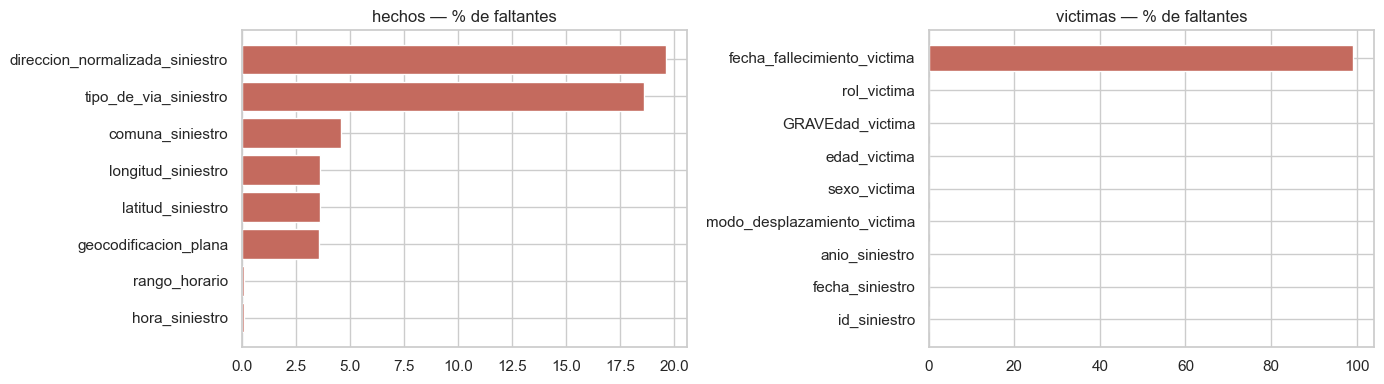

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

faltantes_h = (hechos_raw.isna().mean() * 100).sort_values()
faltantes_h = faltantes_h[faltantes_h > 0]
axes[0].barh(faltantes_h.index, faltantes_h.values, color="#C46A5E")
axes[0].set_title("hechos — % de faltantes")

faltantes_v = (victimas_raw.isna().mean() * 100).sort_values()
faltantes_v = faltantes_v[faltantes_v > 0]
axes[1].barh(faltantes_v.index, faltantes_v.values, color="#C46A5E")
axes[1].set_title("victimas — % de faltantes")

plt.tight_layout()

**Lectura.** Un faltante no siempre es un problema a rellenar:

- `fecha_fallecimiento_victima` vacía significa *la víctima no falleció*. Imputarla sería inventar muertes.
- `direccion_normalizada_siniestro` y las coordenadas vacías son un fallo de geocodificación, no una ubicación desconocida del hecho.
- `comuna_siniestro` vacía sí es información perdida, pero **imputar la moda concentraría artificialmente siniestros en un barrio** y distorsionaría cualquier mapa de riesgo.

La decisión correcta depende del significado de cada variable, no de una regla única.

## 4. Registros duplicados

Distinguimos dos casos que exigen tratamientos opuestos:

- **duplicado exacto**: la fila completa se repite → puede ser un error de carga;
- **duplicado por clave**: mismo `id_siniestro`, filas distintas → puede ser legítimo.

In [78]:
print("hechos — duplicados exactos     :", hechos_raw.duplicated().sum())
print("hechos — id_siniestro repetido  :", hechos_raw.duplicated(subset=["id_siniestro"]).sum())
print("hechos — id_siniestro únicos    :", hechos_raw["id_siniestro"].nunique())

hechos — duplicados exactos     : 0
hechos — id_siniestro repetido  : 0
hechos — id_siniestro únicos    : 65818


In [79]:
print("victimas — duplicados exactos   :", victimas_raw.duplicated().sum())
print("victimas — id_siniestro repetido:", victimas_raw.duplicated(subset=["id_siniestro"]).sum())
print("victimas — id_siniestro únicos  :", victimas_raw["id_siniestro"].nunique())

victimas — duplicados exactos   : 1439
victimas — id_siniestro repetido: 9378
victimas — id_siniestro únicos  : 65818


count    65818.00
mean         1.14
std          0.54
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         26.00
dtype: float64

Siniestros con más de una víctima: 6765


<Axes: title={'center': 'Víctimas por siniestro'}>

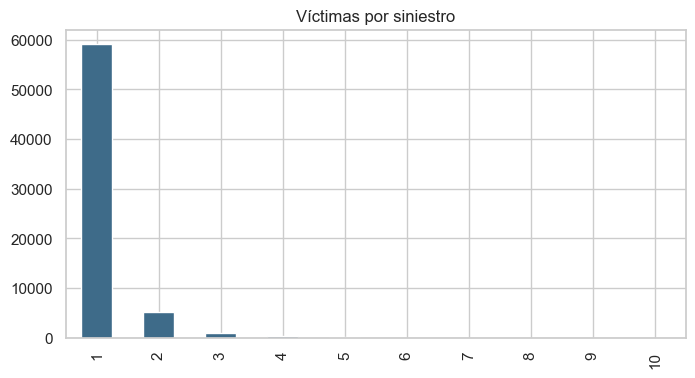

In [80]:
# ¿Cuántas víctimas tiene un siniestro típico?
victimas_por_siniestro = victimas_raw.groupby("id_siniestro").size()

print(victimas_por_siniestro.describe().round(2))
print("\nSiniestros con más de una víctima:", (victimas_por_siniestro > 1).sum())

victimas_por_siniestro.value_counts().sort_index().head(10).plot(
    kind="bar", color="#3E6B89", title="Víctimas por siniestro")

In [81]:
# ¿Las filas de victimas coinciden con el total de víctimas declarado en hechos?
total_declarado = pd.to_numeric(hechos_raw["numero_total_de_victimas"], errors="coerce")

print("suma de víctimas declarada en hechos    :", total_declarado.sum())
print("filas en victimas                       :", len(victimas_raw))
print("filas en victimas sin duplicados exactos:", len(victimas_raw.drop_duplicates()))

suma de víctimas declarada en hechos    : 71917.0
filas en victimas                       : 75197
filas en victimas sin duplicados exactos: 73758


In [82]:
# Integridad referencial hechos <-> victimas
ids_hechos = set(hechos_raw["id_siniestro"])
ids_victimas = set(victimas_raw["id_siniestro"])

print("ids en victimas sin hecho    :", len(ids_victimas - ids_hechos))
print("hechos sin víctima registrada:", len(ids_hechos - ids_victimas))

ids en victimas sin hecho    : 1
hechos sin víctima registrada: 0


> En `victimas`, dos filas idénticas pueden ser **dos personas distintas** con el mismo sexo, edad, rol y gravedad en el mismo siniestro. Antes de eliminar duplicados exactos hay que comprobarlo contra el total declarado (se hace en la sección 16): acá "eliminar duplicados" puede significar **borrar víctimas reales**.

## 5. Explorando variables categóricas

Para cada una: ¿cuántas categorías hay?, ¿cuáles predominan?, ¿hay faltantes?, **¿hay categorías escritas de distintas maneras?**

In [83]:
categoricas_hechos = ["tipo_de_via_siniestro", "modo_desplazamiento_victima",
                      "contraparte_siniestro", "gravedad_siniestro", "comuna_siniestro"]
categoricas_victimas = ["sexo_victima", "GRAVEdad_victima", "rol_victima",
                        "modo_desplazamiento_victima"]

for columna in categoricas_hechos:
    print(f"\n{columna} — {hechos_raw[columna].nunique()} categorías, "
          f"{hechos_raw[columna].isna().sum()} faltantes")
    print(hechos_raw[columna].unique()[:25])


tipo_de_via_siniestro — 5 categorías, 12227 faltantes
<ArrowStringArray>
['AUTOPISTA', 'AVENIDA', nan, 'AV. GRAL. PAZ', 'CALLE', 'SD']
Length: 6, dtype: str

modo_desplazamiento_victima — 14 categorías, 0 faltantes
<ArrowStringArray>
[              'AUTO',               'MOTO',          'BICICLETA',
             'PEATON',                 'SD',               'TAXI',
             'CAMION', 'TRANSPORTE PUBLICO',              'MOVIL',
              'MIXTO',               'OTRO',         'UTILITARIO',
          'MONOPATIN',             '#¡REF!']
Length: 14, dtype: str

contraparte_siniestro — 23 categorías, 0 faltantes
<ArrowStringArray>
[        'UTILITARIO',               'AUTO',             'CAMION',
              'MOVIL', 'TRANSPORTE PUBLICO',               'MOTO',
                 'SD',               'TAXI',        'OBJETO FIJO',
          'BICICLETA',               'OTRO',           'MULTIPLE',
             'PEATON',          'MONOPATIN',               'TREN',
               'auto', 

In [84]:
for columna in categoricas_victimas:
    print(f"\n{columna} — {victimas_raw[columna].nunique()} categorías, "
          f"{victimas_raw[columna].isna().sum()} faltantes")
    print(victimas_raw[columna].unique()[:25])


sexo_victima — 3 categorías, 4 faltantes
<ArrowStringArray>
['F', 'M', 'SD', nan]
Length: 4, dtype: str

GRAVEdad_victima — 4 categorías, 4 faltantes
<ArrowStringArray>
['GRAVE', 'MORTAL', 'LEVE', 'mortal', nan]
Length: 5, dtype: str

rol_victima — 9 categorías, 4 faltantes
<ArrowStringArray>
[ 'CICLISTA', 'CONDUCTOR', 'conductor',  'PASAJERO',    'PEATON',        'SD',
 'Conductor',  'Pasajero',        'sd',         nan]
Length: 10, dtype: str

modo_desplazamiento_victima — 18 categorías, 4 faltantes
<ArrowStringArray>
[         'BICICLETA',               'MOTO',               'AUTO',
 'TRANSPORTE PUBLICO',         'UTILITARIO',             'PEATON',
                 'SD',               'TAXI',              'MOVIL',
          'MONOPATIN',               'OTRO',             'CAMION',
               'moto',               'auto',          'monopatin',
              'MIXTO',             'camion',             'peaton',
                  nan]
Length: 19, dtype: str


In [85]:
hechos_raw["gravedad_siniestro"].value_counts(normalize=True).round(4) * 100

gravedad_siniestro
LEVE      94.46
GRAVE      4.49
MORTAL     1.05
Name: proportion, dtype: float64

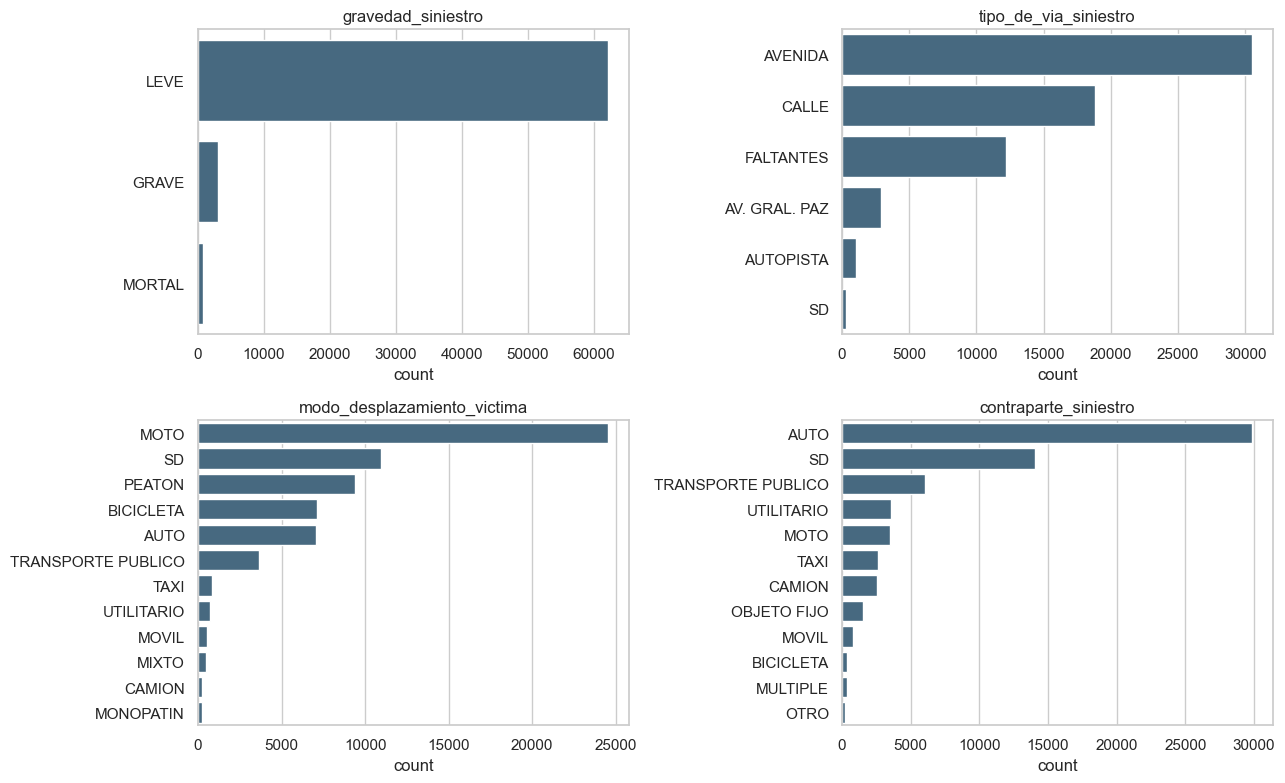

In [86]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, columna in zip(axes.ravel(), ["gravedad_siniestro", "tipo_de_via_siniestro",
                                      "modo_desplazamiento_victima", "contraparte_siniestro"]):
    grafico = hechos_raw[columna].fillna("FALTANTES")
    sns.countplot(y=grafico, order=grafico.value_counts().index[:12], ax=ax, color="#3E6B89")
    ax.set_title(columna)
    ax.set_ylabel("")

plt.tight_layout()

### Distribución por comuna

`comuna_siniestro` viene como texto (`"Comuna 8"`, `"COMUNA 3"`, `"12"`, `"SD"`). Para poder graficarla hay que quedarse con el número. Esto es sólo diagnóstico: la conversión definitiva se hace en la sección 12.

comunas no interpretables o faltantes: 3552


<Axes: title={'center': 'Siniestros por comuna'}, xlabel='comuna', ylabel='siniestros'>

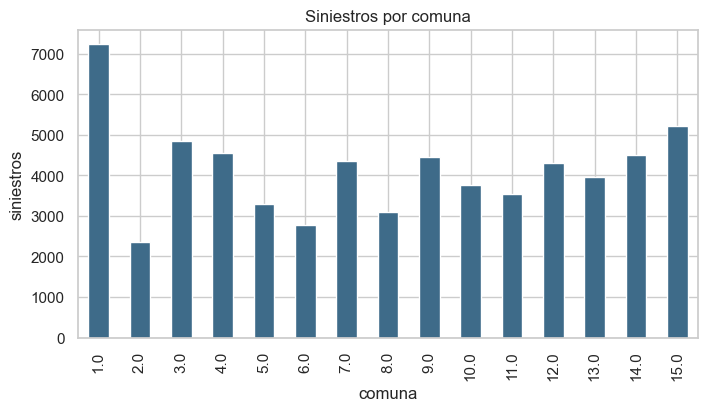

In [87]:
comuna = hechos_raw["comuna_siniestro"].str.extract(r"(\d+)")[0].astype(float)

print("comunas no interpretables o faltantes:", comuna.isna().sum())

comuna.value_counts().sort_index().plot(
    kind="bar", color="#3E6B89",
    title="Siniestros por comuna", xlabel="comuna", ylabel="siniestros")

In [88]:
# Siniestros distintos por comuna y año
pd.crosstab(comuna, hechos_raw["anio_siniestro"])

anio_siniestro,2019,2020,2021,2022,2023,2024,2025
0,,,,,,,
1.0,1109,632,816,1015,1137,1132,1400
2.0,404,196,288,336,337,374,415
3.0,708,467,561,712,766,783,861
4.0,721,460,575,668,675,621,842
5.0,504,333,401,431,467,483,666
6.0,418,250,297,462,403,425,517
7.0,636,412,487,638,653,711,831
8.0,481,255,347,471,455,471,608
9.0,718,417,565,609,670,674,797


## 6. El mismo dato escrito de distintas maneras

Este es el hallazgo central del diagnóstico categórico. Contamos cuántas categorías **colapsan** al normalizar (quitar espacios → mayúsculas → sin acentos). La diferencia entre el conteo crudo y el normalizado son categorías artificiales: no son fenómenos distintos, son tipeos distintos.

In [89]:
for columna in ["tipo_de_via_siniestro", "modo_desplazamiento_victima",
                "contraparte_siniestro", "gravedad_siniestro"]:
    normalizada = (hechos_raw[columna].str.strip().str.upper()
                   .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))
    print(f"{columna:32s} crudas: {hechos_raw[columna].nunique():3d}   "
          f"normalizadas: {normalizada.nunique():3d}   "
          f"colapsadas: {hechos_raw[columna].nunique() - normalizada.nunique():3d}")

tipo_de_via_siniestro            crudas:   5   normalizadas:   5   colapsadas:   0
modo_desplazamiento_victima      crudas:  14   normalizadas:  14   colapsadas:   0
contraparte_siniestro            crudas:  23   normalizadas:  17   colapsadas:   6
gravedad_siniestro               crudas:   3   normalizadas:   3   colapsadas:   0


In [90]:
for columna in ["sexo_victima", "GRAVEdad_victima", "rol_victima", "modo_desplazamiento_victima"]:
    normalizada = (victimas_raw[columna].str.strip().str.upper()
                   .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))
    print(f"{columna:32s} crudas: {victimas_raw[columna].nunique():3d}   "
          f"normalizadas: {normalizada.nunique():3d}   "
          f"colapsadas: {victimas_raw[columna].nunique() - normalizada.nunique():3d}")

sexo_victima                     crudas:   3   normalizadas:   3   colapsadas:   0
GRAVEdad_victima                 crudas:   4   normalizadas:   3   colapsadas:   1
rol_victima                      crudas:   9   normalizadas:   5   colapsadas:   4
modo_desplazamiento_victima      crudas:  18   normalizadas:  13   colapsadas:   5


In [91]:
# Qué variantes concretas colapsan en una misma categoría
normalizada = (victimas_raw["rol_victima"].str.strip().str.upper()
               .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))

pd.crosstab(normalizada, victimas_raw["rol_victima"])

rol_victima,CICLISTA,CONDUCTOR,Conductor,PASAJERO,PEATON,Pasajero,SD,conductor,sd
rol_victima,,,,,,,,,
CICLISTA,6281,0,0,0,0,0,0,0,0
CONDUCTOR,0,220,43,0,0,0,0,44,0
PASAJERO,0,0,0,60,0,4,0,0,0
PEATON,0,0,0,0,8405,0,0,0,0
SD,0,0,0,0,0,0,60127,0,9


Además de la normalización tipográfica hacen falta **diccionarios de equivalencias semánticas**, que ninguna función automática puede resolver: `AUTO-UTILITARIO` y `UTILITARIO` son el mismo modo; `BUS` y `OMNIBUS` son `COLECTIVO`; `MOTOCICLETA` y `CICLOMOTOR` son `MOTO`.

El criterio para la Parte 2: **reducir categorías artificiales sin borrar diferencias reales.** Unificar `CAMIONETA` con `AUTO` es defendible (masa y protección similares); unificar `MOTO` con `AUTO` no lo es.

## 7. Distribución de la edad de las víctimas

¿Cuál es la media y la mediana?, ¿el mínimo y el máximo?, ¿es simétrica?, ¿hay valores imposibles?

In [92]:
edad = pd.to_numeric(victimas_raw["edad_victima"], errors="coerce")

print("media    :", edad.mean().round(2))
print("mediana  :", edad.median())
print("asimetría:", edad.skew().round(3))
edad.describe().round(2)

media    : 37.94
mediana  : 35.0
asimetría: 0.755


count    51821.00
mean        37.94
std         15.82
min          0.00
25%         26.00
50%         35.00
75%         47.00
max        116.00
Name: edad_victima, dtype: float64

In [93]:
print("edades imposibles (> 110):", (edad > 110).sum())
print("edades imposibles (< 0)  :", (edad < 0).sum())

victimas_raw[edad > 110].head()

edades imposibles (> 110): 1
edades imposibles (< 0)  : 0


,id_siniestro,fecha_siniestro,anio_siniestro,modo_desplazamiento_victima,sexo_victima,edad_victima,GRAVEdad_victima,rol_victima,fecha_fallecimiento_victima
19213,LC-2025-0400556,2025-5-27,2025.0,MOTO,F,116,LEVE,SD,NaN


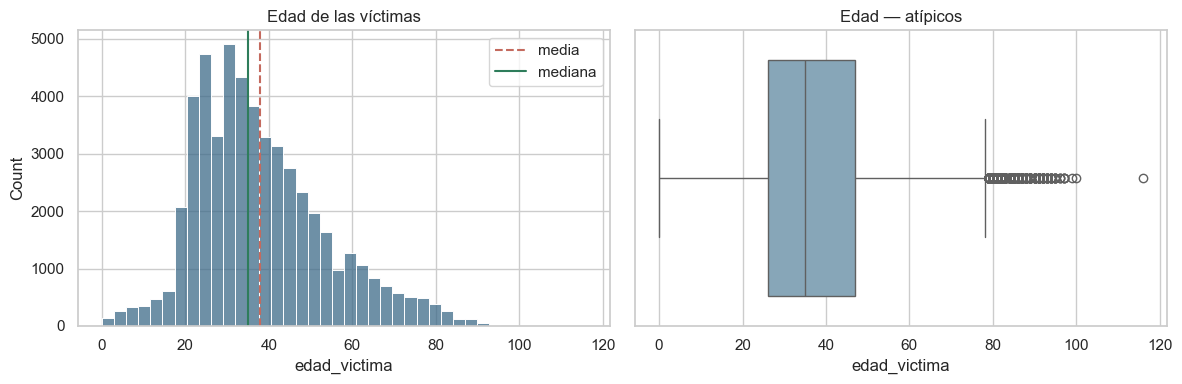

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(edad, bins=40, ax=axes[0], color="#3E6B89")
axes[0].axvline(edad.mean(), color="#C46A5E", linestyle="--", label="media")
axes[0].axvline(edad.median(), color="#2E7D5B", label="mediana")
axes[0].legend()
axes[0].set_title("Edad de las víctimas")

sns.boxplot(x=edad, ax=axes[1], color="#7FA8C0")
axes[1].set_title("Edad — atípicos")

plt.tight_layout()

**Lectura.** La distribución es **asimétrica positiva** (cola larga hacia las edades altas) y la media queda por encima de la mediana. Para imputar, la mediana es la medida robusta; la media se desplazaría por los extremos.

Las edades por encima de 110 no son atípicos: son **errores**. Un atípico plausible se marca; un valor imposible se corrige o se convierte en faltante.

## 8. Valores atípicos en las variables numéricas

Un valor atípico no siempre es un error. La pregunta no es "¿lo elimino?" sino **"¿es posible y tiene sentido dentro del problema?"**

In [95]:
numericas = ["numero_total_de_victimas", "numero_victimas_leve_siniestro",
             "numero_victimas_grave_siniestro", "numero_victimas_mortal_siniestro"]

# Estas columnas traen textos como "SD": hay que convertirlas para poder analizarlas.
hechos_numericas = hechos_raw[numericas].apply(pd.to_numeric, errors="coerce")

print("valores no numéricos por columna:")
print(hechos_numericas.isna().sum() - hechos_raw[numericas].isna().sum())

hechos_numericas.describe().round(2)

valores no numéricos por columna:
numero_total_de_victimas            3276
numero_victimas_leve_siniestro         0
numero_victimas_grave_siniestro        0
numero_victimas_mortal_siniestro       0
dtype: int64


,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro
count,62542.00,65818.00,65818.00,65818.00
mean,1.15,1.08,0.05,0.01
std,0.55,0.58,0.23,0.10
min,1.00,0.00,0.00,0.00
25%,1.00,1.00,0.00,0.00
50%,1.00,1.00,0.00,0.00
75%,1.00,1.00,0.00,0.00
max,26.00,26.00,10.00,2.00


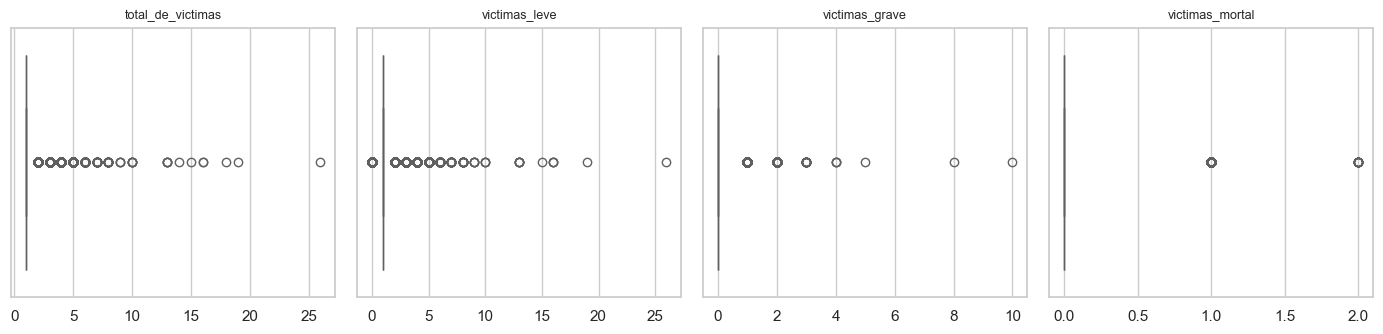

In [96]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for ax, columna in zip(axes, numericas):
    sns.boxplot(x=hechos_numericas[columna], ax=ax, color="#7FA8C0")
    ax.set_title(columna.replace("numero_", "").replace("_siniestro", ""), fontsize=9)
    ax.set_xlabel("")

plt.tight_layout()

In [97]:
# Bigote superior de Tukey: Q3 + 1.5 * IQR
q1 = hechos_numericas["numero_total_de_victimas"].quantile(0.25)
q3 = hechos_numericas["numero_total_de_victimas"].quantile(0.75)
bigote_superior = q3 + 1.5 * (q3 - q1)

print("bigote superior:", bigote_superior)
print("siniestros por encima del bigote:",
      (hechos_numericas["numero_total_de_victimas"] > bigote_superior).sum())

# Ojo: en una variable de conteo tan concentrada (la mayoría tiene 1 víctima) el criterio
# IQR marca como "atípico" cualquier siniestro con 2 o más. No es un error: es un
# siniestro múltiple. El criterio estadístico no reemplaza al criterio del dominio.

bigote superior: 1.0
siniestros por encima del bigote: 6766


coordenadas fuera de CABA: 0
coordenadas faltantes    : 3031


Text(0.5, 1.0, 'Siniestros geolocalizados')

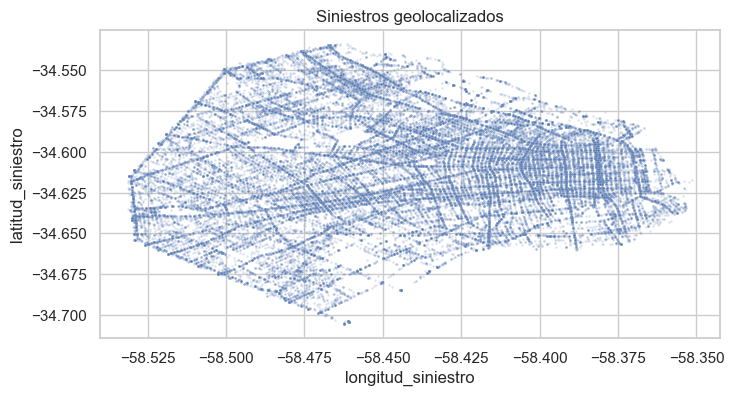

In [98]:
# Coordenadas: ¿hay puntos fuera de CABA? (límites aproximados de la Ciudad)
latitud = pd.to_numeric(hechos_raw["latitud_siniestro"], errors="coerce")
longitud = pd.to_numeric(hechos_raw["longitud_siniestro"], errors="coerce")

fuera_de_caba = ((~latitud.between(-34.71, -34.52) | ~longitud.between(-58.54, -58.33))
                 & latitud.notna())

print("coordenadas fuera de CABA:", fuera_de_caba.sum())
print("coordenadas faltantes    :", latitud.isna().sum())

sns.scatterplot(x=longitud[~fuera_de_caba], y=latitud[~fuera_de_caba], s=3, alpha=0.2)
plt.title("Siniestros geolocalizados")

In [99]:
# Hora: ¿valores fuera de 0-23?
hora = pd.to_datetime(hechos_raw["hora_siniestro"], errors="coerce", format="mixed").dt.hour

print("horas no interpretables:", hora.isna().sum() - hechos_raw["hora_siniestro"].isna().sum())
print("horas fuera de 0-23    :", (~hora.between(0, 23)).sum() - hora.isna().sum())

horas no interpretables: 4
horas fuera de 0-23    : 0


**Criterio adoptado** (se decide acá, se ejecuta en la sección 14)

| Caso | Diagnóstico | Acción |
|---|---|---|
| `numero_total_de_victimas` alto | siniestro múltiple, poco frecuente pero **real** | se marca con un flag, **no se elimina** |
| `edad_victima` > 110 | **imposible** | → faltante, luego imputación por mediana |
| `hora` fuera de 0–23 | **imposible** | → faltante |
| `comuna` fuera de 1–15 | **imposible** | → faltante |
| coordenadas fuera de CABA | error de **geocodificación** | → faltante |

El flag `flag_atipico_victimas` permite después analizar los datos con y sin esos casos sin haber perdido información.

## 9. Coherencia interna: una validación que los faltantes no detectan

Un dato puede estar presente y aun así ser incorrecto. En `hechos`, la suma de víctimas por gravedad debe igualar el total. Y la gravedad declarada en `gravedad_siniestro` debe ser coherente con los conteos.

In [100]:
suma_por_gravedad = hechos_numericas[["numero_victimas_leve_siniestro",
                                      "numero_victimas_grave_siniestro",
                                      "numero_victimas_mortal_siniestro"]].sum(axis=1)

incoherentes = suma_por_gravedad != hechos_numericas["numero_total_de_victimas"]

print("filas donde leve + grave + mortal != total:", incoherentes.sum())
print("porcentaje:", round(incoherentes.mean() * 100, 2), "%")

filas donde leve + grave + mortal != total: 3278
porcentaje: 4.98 %


In [101]:
# Gravedad derivada de los conteos: MORTAL si hubo muertos, GRAVE si hubo graves, si no LEVE
gravedad_derivada = pd.Series("LEVE", index=hechos_raw.index)
gravedad_derivada[hechos_numericas["numero_victimas_grave_siniestro"] > 0] = "GRAVE"
gravedad_derivada[hechos_numericas["numero_victimas_mortal_siniestro"] > 0] = "MORTAL"

gravedad_declarada = hechos_raw["gravedad_siniestro"].str.strip().str.upper()

print("discrepancias declarada vs. derivada:", (gravedad_declarada != gravedad_derivada).sum())

pd.crosstab(gravedad_declarada.fillna("FALTANTE"), gravedad_derivada)

discrepancias declarada vs. derivada: 31


col_0,GRAVE,LEVE,MORTAL
gravedad_siniestro,,,
GRAVE,2955,0,0
LEVE,31,62143,0
MORTAL,0,0,689


In [102]:
# Otra regla verificable: quien tiene fecha de fallecimiento debería figurar como MORTAL
fallecio = victimas_raw["fecha_fallecimiento_victima"].notna()
dice_mortal = victimas_raw["GRAVEdad_victima"].str.strip().str.upper() == "MORTAL"

print("con fecha de fallecimiento pero gravedad != MORTAL:", (fallecio & ~dice_mortal).sum())
print("MORTAL sin fecha de fallecimiento                 :", (~fallecio & dice_mortal).sum())

con fecha de fallecimiento pero gravedad != MORTAL: 0
MORTAL sin fecha de fallecimiento                 : 0


Cuando dos campos de la misma fuente se contradicen hay que elegir uno y justificarlo. Acá se prioriza la **gravedad derivada de los conteos**: los conteos son la base de cálculo de los indicadores oficiales y son verificables aritméticamente, mientras el campo de texto es una etiqueta resumen.